### Import libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import joblib

### Load the dataset

In [2]:
df = pd.read_csv(
    "data/student_placement_prediction_dataset_2026.csv"
)

# Display the first 5 rows

df.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


### Dataset shape

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 100000
Columns: 26


### Column names

In [4]:
print(df.columns.tolist())

['student_id', 'age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day', 'placement_status', 'salary_package_lpa']


### Data types

In [5]:
print(df.dtypes)

student_id                     int64
age                            int64
gender                           str
cgpa                         float64
branch                           str
college_tier                     str
internships_count              int64
projects_count                 int64
certifications_count           int64
coding_skill_score           float64
aptitude_score               float64
communication_skill_score    float64
logical_reasoning_score      float64
hackathons_participated        int64
github_repos                   int64
linkedin_connections           int64
mock_interview_score         float64
attendance_percentage        float64
backlogs                       int64
extracurricular_score        float64
leadership_score             float64
volunteer_experience             str
sleep_hours                  float64
study_hours_per_day          float64
placement_status                 str
salary_package_lpa           float64
dtype: object


### Dataset information

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   student_id                 100000 non-null  int64  
 1   age                        100000 non-null  int64  
 2   gender                     100000 non-null  str    
 3   cgpa                       100000 non-null  float64
 4   branch                     100000 non-null  str    
 5   college_tier               100000 non-null  str    
 6   internships_count          100000 non-null  int64  
 7   projects_count             100000 non-null  int64  
 8   certifications_count       100000 non-null  int64  
 9   coding_skill_score         100000 non-null  float64
 10  aptitude_score             100000 non-null  float64
 11  communication_skill_score  100000 non-null  float64
 12  logical_reasoning_score    100000 non-null  float64
 13  hackathons_participated    100000 non-nul

### Statistical summary

In [7]:
df.describe()

,student_id,age,cgpa,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,...,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,sleep_hours,study_hours_per_day,salary_package_lpa
count,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,21.005740,7.496890,1.50223,3.001860,2.005150,69.825326,64.988108,67.960744,65.931696,...,4.005160,524.559110,69.989411,84.730169,0.497590,59.894049,54.937526,6.983319,3.523124,7.252106
std,28867.657797,1.999562,0.992834,1.22528,1.731764,1.416553,14.694618,14.844093,13.846636,14.826790,...,2.004897,274.993479,11.937257,9.416075,0.708434,19.549666,19.781197,1.468113,1.471248,6.735132
min,1.000000,18.000000,4.500000,0.00000,0.000000,0.000000,20.000000,20.000000,20.000000,20.000000,...,0.000000,50.000000,20.000000,50.000000,0.000000,0.000000,0.000000,3.000000,0.500000,0.000000
25%,25000.750000,19.000000,6.820000,1.00000,2.000000,1.000000,59.807945,54.894600,58.587535,55.940547,...,3.000000,287.000000,61.973172,78.325833,0.000000,46.538590,41.432390,6.000000,2.500000,0.000000
50%,50000.500000,21.000000,7.500000,1.00000,3.000000,2.000000,70.006250,65.011394,67.973221,66.003829,...,4.000000,523.000000,70.026665,85.018828,0.000000,60.079021,55.076210,7.000000,3.500000,11.100000
75%,75000.250000,23.000000,8.180000,2.00000,4.000000,3.000000,80.058762,75.079266,77.503749,76.113705,...,5.000000,764.000000,78.122083,91.782511,1.000000,73.549567,68.530115,8.000000,4.500000,13.470000
max,100000.000000,24.000000,10.000000,8.00000,13.000000,11.000000,100.000000,100.000000,100.000000,100.000000,...,16.000000,999.000000,100.000000,100.000000,6.000000,100.000000,100.000000,10.000000,10.000000,20.440000


### Missing values

In [8]:
df.isnull().sum()

student_id                   0
age                          0
gender                       0
cgpa                         0
branch                       0
college_tier                 0
internships_count            0
projects_count               0
certifications_count         0
coding_skill_score           0
aptitude_score               0
communication_skill_score    0
logical_reasoning_score      0
hackathons_participated      0
github_repos                 0
linkedin_connections         0
mock_interview_score         0
attendance_percentage        0
backlogs                     0
extracurricular_score        0
leadership_score             0
volunteer_experience         0
sleep_hours                  0
study_hours_per_day          0
placement_status             0
salary_package_lpa           0
dtype: int64

### Duplicate records

In [9]:
df.duplicated().sum()

np.int64(0)

### Target distribution

In [10]:
df["placement_status"].value_counts()

placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64

 ### EDA - CGPA vs Placement Status

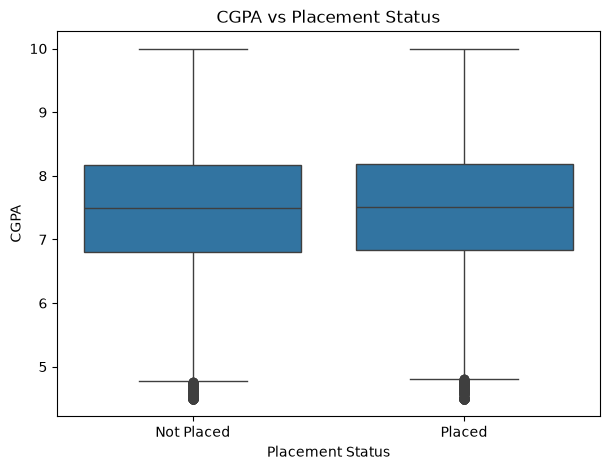

In [11]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="placement_status",
    y="cgpa"
)

plt.title("CGPA vs Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("CGPA")

plt.show()

### EDA - Internship Experience vs Placement

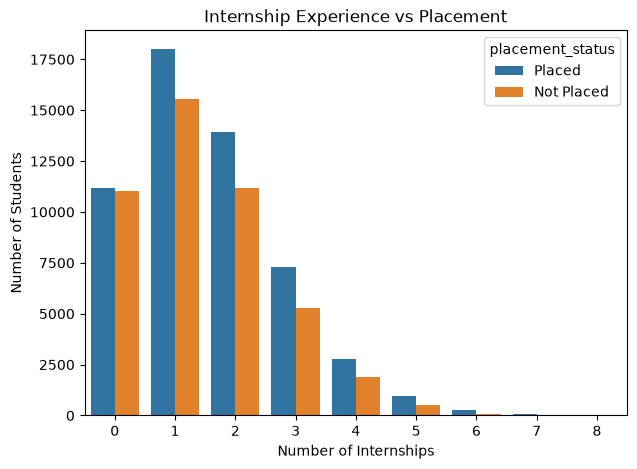

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="internships_count",
    hue="placement_status"
)

plt.title("Internship Experience vs Placement")
plt.xlabel("Number of Internships")
plt.ylabel("Number of Students")

plt.show()

### EDA - College Tier vs Placement Status

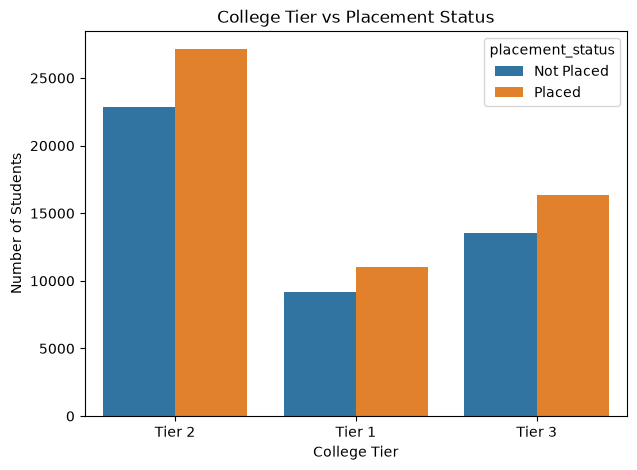

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="college_tier",
    hue="placement_status"
)

plt.title("College Tier vs Placement Status")
plt.xlabel("College Tier")
plt.ylabel("Number of Students")

plt.show()

###  Data Preprocessing

In [14]:
# Define the target variable
target = "placement_status"

print("Target variable:", target)

Target variable: placement_status


In [15]:
# Check target classes
print(df[target].unique())
print(df[target].value_counts())

<ArrowStringArray>
['Not Placed', 'Placed']
Length: 2, dtype: str
placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64


### Separate features and target

In [16]:
# Separate input features and target
X = df.drop(columns=[target])
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (100000, 25)
Target shape: (100000,)


In [17]:
# Remove student ID because it is only an identifier
if "student_id" in X.columns:
    X = X.drop(columns=["student_id"])

print("Features after removing ID:", X.shape)

Features after removing ID: (100000, 24)


In [18]:
# Identify categorical columns
categorical_columns = X.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['gender', 'branch', 'college_tier', 'volunteer_experience']


C:\Users\ABHIJAY KANOJIYA\AppData\Local\Temp\ipykernel_21052\389853499.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include="object").columns


In [19]:
# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['age', 'cgpa', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'sleep_hours', 'study_hours_per_day', 'salary_package_lpa']


### Encode Categorical Features

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

print("Categorical encoding setup completed.")

Categorical encoding setup completed.


### Train-Test Split

In [21]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80000, 24)
Testing data: (20000, 24)


### Numerical Feature Scaling

In [22]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns again after removing student_id
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['age', 'cgpa', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'sleep_hours', 'study_hours_per_day', 'salary_package_lpa']


### Create Preprocessing Pipeline

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for categorical and numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Model Building

###  Logistic Regression

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


### Decision Tree

In [25]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=42,
            max_depth=5
        ))
    ]
)

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


###  Random Forest

In [26]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            max_depth=10,
            n_jobs=-1
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


###  XGBoost

In [27]:
print("Target data type:", y.dtype)

print("Unique target values:")   #That cell is only for checking the target, not for fixing it.
print(y.unique())

print("\nTarget value counts:")
print(y.value_counts())

Target data type: str
Unique target values:
<ArrowStringArray>
['Not Placed', 'Placed']
Length: 2, dtype: str

Target value counts:
placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64


In [28]:
print("Training target unique values:")
print(y_train.unique())

print("\nTraining target data type:")
print(y_train.dtype)

Training target unique values:
<ArrowStringArray>
['Placed', 'Not Placed']
Length: 2, dtype: str

Training target data type:
str


In [29]:
# Convert target labels into numerical values
y = y.map({
    "Not Placed": 0,
    "Placed": 1
})

print("Target classes after encoding:")
print(y.unique())

Target classes after encoding:
[0 1]


In [30]:
# Recreate train-test split after target encoding
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training target classes:")
print(y_train.unique())

print("\nTesting target classes:")
print(y_test.unique())

Training target classes:
[1 0]

Testing target classes:
[0 1]


In [31]:
xgb_model.fit(X_train, y_train)

print("XGBoost trained successfully.")

NameError: name 'xgb_model' is not defined

### checking and recreate train test split

In [ ]:
print("y_test values:")
print(y_test.unique())

print("\nLogistic Regression predictions:")
print(y_pred_lr[:10])

y_test values:
[0 1]

Logistic Regression predictions:
['Not Placed' 'Not Placed' 'Not Placed' 'Placed' 'Placed' 'Not Placed'
 'Placed' 'Placed' 'Not Placed' 'Not Placed']


In [ ]:
# Recreate train-test split using the encoded target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training target:")
print(y_train.unique())

print("\nTesting target:")
print(y_test.unique())

Training target:
[1 0]

Testing target:
[0 1]


#### RETRAIN ALL FOUR MODELS

Because we recreated the split, retrain the models again.

Logistic Regression

In [ ]:
logistic_model.fit(X_train, y_train)
print("Logistic Regression retrained.")

Logistic Regression retrained.


Decision Tree

In [ ]:
decision_tree_model.fit(X_train, y_train)
print("Decision Tree retrained.")

Decision Tree retrained.


Random Forest

In [ ]:
random_forest_model.fit(X_train, y_train)
print("Random Forest retrained.")

Random Forest retrained.


XGBoost

In [ ]:
xgb_model.fit(X_train, y_train)
print("XGBoost retrained.")

XGBoost retrained.


##  Model Evaluation

### Evaluate Logistic Regression

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Make predictions
y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression")
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

Logistic Regression
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


### CHECKING DATA LEAKAGE

In [ ]:
print("Features used by the model:")
print(X.columns.tolist())

Features used by the model:
['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day', 'salary_package_lpa']


In [ ]:
# Check correlation of numerical features with placement
correlation = df.select_dtypes(
    include=["int64", "float64"]
).corr()["placement_status"] if "placement_status" in df.select_dtypes(include=["int64", "float64"]).columns else None

print(correlation)

None


### WE ARE CHECKING: WHY ACCURACY IS 100%

In [ ]:
print("Features used for prediction:")
print(X.columns.tolist())

Features used for prediction:
['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day', 'salary_package_lpa']


In [ ]:
print("Possible leakage-related columns:")

for col in X.columns:
    if any(word in col.lower() for word in ["salary", "package", "placement", "offer", "job", "company"]):
        print(col)

Possible leakage-related columns:
salary_package_lpa


###  Check and Remove Potential Data Leakage

check the relationship

In [ ]:
# Check salary package for each placement status
print(
    df.groupby("placement_status")["salary_package_lpa"]
      .describe()
)

                    count       mean       std   min    25%   50%    75%  \
placement_status                                                           
Not Placed        45541.0   0.000000  0.000000  0.00   0.00   0.0   0.00   
Placed            54459.0  13.316635  1.592418  7.11  12.23  13.3  14.39   

                    max  
placement_status         
Not Placed         0.00  
Placed            20.44  


Check whether unplaced students have salary values

In [ ]:
print(
    df.groupby("placement_status")["salary_package_lpa"]
      .apply(lambda x: x.notna().sum())
)

placement_status
Not Placed    45541
Placed        54459
Name: salary_package_lpa, dtype: int64


In [ ]:
print(
    df.groupby("placement_status")["salary_package_lpa"]
      .mean()
)

placement_status
Not Placed     0.000000
Placed        13.316635
Name: salary_package_lpa, dtype: float64


### Remove Post-Placement Feature

In [ ]:
# Remove salary package because it is known after placement
X = X.drop(columns=["salary_package_lpa"])

print("salary_package_lpa removed.")
print("Remaining features:", X.shape[1])

salary_package_lpa removed.
Remaining features: 23


## REBUILD THE TRAINING DATA

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80000, 23)
Testing data: (20000, 23)


### UPDATE DATA PREPROCESSING AFTER LEAKAGE REMOVAL

In [ ]:
# Update feature types
# Update categorical and numerical columns after removing salary_package_lpa

categorical_columns = X.select_dtypes(include="object").columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Categorical columns:")
print(categorical_columns.tolist())

print("\nNumerical columns:")
print(numerical_columns.tolist())

Categorical columns:
['gender', 'branch', 'college_tier', 'volunteer_experience']

Numerical columns:
['age', 'cgpa', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'sleep_hours', 'study_hours_per_day']


C:\Users\ABHIJAY KANOJIYA\AppData\Local\Temp\ipykernel_15300\362168045.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include="object").columns


In [ ]:
# Create updated preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

print("Updated preprocessing pipeline created successfully.")

Updated preprocessing pipeline created successfully.


### RETRAIN MODELS AFTER LEAKAGE REMOVAL

In [ ]:
print("Current X columns:")
print(X.columns.tolist())

print("\nCategorical columns:")
print(categorical_columns.tolist())

print("\nNumerical columns:")
print(numerical_columns.tolist())

Current X columns:
['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day']

Categorical columns:
['gender', 'branch', 'college_tier', 'volunteer_experience']

Numerical columns:
['age', 'cgpa', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'sleep_hours', 'study_hours_per_day']


In [ ]:
# Recalculate feature types from the current X
categorical_columns = X.select_dtypes(include=["object", "string"]).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Updated categorical columns:")
print(categorical_columns)

print("\nUpdated numerical columns:")
print(numerical_columns)

Updated categorical columns:
['gender', 'branch', 'college_tier', 'volunteer_experience']

Updated numerical columns:
['age', 'cgpa', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'sleep_hours', 'study_hours_per_day']


### NOW REBUILD THE PREPROCESSOR

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

print("Preprocessor rebuilt successfully.")

Preprocessor rebuilt successfully.


### NOW REBUILD LOGISTIC REGRESSION PIPELINE

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

print("Logistic Regression pipeline updated.")

Logistic Regression pipeline updated.


In [ ]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression retrained successfully.")

Logistic Regression retrained successfully.


## MODEL EVALUATION

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_pred = logistic_model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.57005
Precision: 0.5788894240693594
Recall   : 0.77240176276166
F1 Score : 0.6617895771878073

Confusion Matrix:
[[2988 6120]
 [2479 8413]]


### MODEL SAVING

In [ ]:
import joblib

joblib.dump(logistic_model, "placement_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [32]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=100,
            max_depth=5,
            learning_rate=0.1,
            eval_metric="logloss",
            random_state=42
        ))
    ]
)